# Chapter 6: Neural Networks

### Data from Ch 5.

In [2]:
# Traning and Validation data from ch. 5

import torch
t_c = [0.5, 14.0, 15.0, 28.0, 11.0, 8.0, 3.0, -4.0, 6.0, 13.0, 21.0] # Measured Temp in C
t_u = [35.7, 55.9, 58.2, 81.9, 56.3, 48.9, 33.9, 21.8, 48.4, 60.4, 68.4] # Thermometer readings (unknown Units)
t_c = torch.tensor(t_c).unsqueeze(1)
t_u = torch.tensor(t_u).unsqueeze(1)

t_u.shape

n_samples = t_u.shape[0]
n_val = int(0.2 * n_samples)

shuffled_idxs = torch.randperm(n_samples)
train_idxs = shuffled_idxs[:-n_val] # ALl but last 2 idxs
val_idxs = shuffled_idxs[-n_val:]

train_idxs, val_idxs

t_un_train = t_u[train_idxs] * 0.1
t_un_val = t_u[val_idxs] * 0.1

t_c_train = t_c[train_idxs]
t_c_val = t_c[val_idxs]

## Creating a Linear Model with torch.nn - Recreating Ch 5. Model with a neural network

- torch.nn provides all the building blocks (modules/layers) to create a neural nerwork
- nn.Linear creates a linear neural network - Equivelent to the model in ch 5.

- Forward Pass uses call method __ call __ \
--> The call method of all nn submodules (like nn.linear) is pre-defined and allows you to call the nn like a function \
--> __ call __ takes care of some work (hooks) on the data and then calls .forward()
- Model Features \
--> Refers to the size of the input and the output tensor for the module \
--> Accociated with Model Capacity 

In [3]:
import torch.nn as nn

linear_model = nn.Linear(1, 1)  #Constructor Argument nn.Module(input features, output features, and if model has a bias (default=True))
linear_model(t_un_val)  # forward pass through nn (using it's __call__ method)

# We now have a linear NN with one input, one output its weight and bias  
linear_model.weight, linear_model.bias 



(Parameter containing:
 tensor([[-0.3589]], requires_grad=True),
 Parameter containing:
 tensor([0.8492], requires_grad=True))

#### Calling module on input
- Modules expect the first element in the tensor to be the batch size \
--> Designed to produce outputs on a batch to leverage paralization

In [4]:
x = torch.ones(1)
linear_model(x) # Will still work

x = torch.ones(10, 1) # What should be done
linear_model(x) # Pass input tensor of size Batch x Nin (

tensor([[0.4903],
        [0.4903],
        [0.4903],
        [0.4903],
        [0.4903],
        [0.4903],
        [0.4903],
        [0.4903],
        [0.4903],
        [0.4903]], grad_fn=<AddmmBackward0>)

In [5]:
# Reshaping model inputs to add batch size - Using unsqueeze
t_c = [0.5, 14.0, 15.0, 28.0, 11.0, 8.0, 3.0, -4.0, 6.0, 13.0, 21.0]
t_u = [35.7, 55.9, 58.2, 81.9, 56.3, 48.9, 33.9, 21.8, 48.4, 60.4, 68.4]

t_c = torch.tensor(t_c).unsqueeze(1) 
t_u = torch.tensor(t_u).unsqueeze(1)

t_u.shape # Batch size x Input Featues

torch.Size([11, 1])

### Updating the training Loop

- Parameters are now a member of the nn.Module --> This is what now gets passed to optimizer \
--> Returns a list of parameters for the module and all of its submodules

In [6]:
import torch
import torch.nn as nn
import torch.optim as optim

linear_model = nn.Linear(1, 1)
optimizer = optim.SGD(
    linear_model.parameters(), # Replaces [params]
    lr = 1e-2)

linear_model.parameters(), list(linear_model.parameters())

(<generator object Module.parameters at 0x7f6cbc98af80>,
 [Parameter containing:
  tensor([[-0.6608]], requires_grad=True),
  Parameter containing:
  tensor([-0.4990], requires_grad=True)])

In [7]:
def training_loop(n_epochs, optimizer, model, loss_fn, t_u_train, t_u_val, t_c_train, t_c_val):
    # Notice that model is passed instead of params
    for epoch in range(1, n_epochs + 1):
        t_p_train = model(t_u_train)  # You just pass the data -- Params are part of model!
        loss_train = loss_fn(t_p_train, t_c_train)
       
        with torch.no_grad():
            t_p_val = model(t_u_val)
            loss_val = loss_fn(t_p_val, t_c_val)

        optimizer.zero_grad()
        loss_train.backward()
        optimizer.step()

        if epoch <= 3 or epoch % 1000 == 0:
            print(f'EPOCH {epoch}, Training loss: {loss_train.item():.4f}, Validation loss: {loss_val.item():.4f}')  
        

- Using Loss Functions from torch.nn \
--> There are several loss functions as a subclass of the nn.Module \
--> MSELoss (Mean Squared Error) is the same as the loss function defined in ch 5.

In [8]:
linear_model = nn.Linear(1,1)
lr = 1e-2
optimizer = optim.SGD(linear_model.parameters(), lr=lr)

training_loop(
    n_epochs=3000,
    optimizer=optimizer,
    model=linear_model,
    loss_fn = nn.MSELoss(),
    t_u_train = t_un_train,
    t_u_val = t_un_val,
    t_c_train = t_c_train,
    t_c_val= t_c_val)

print()
print(linear_model.weight)
print(linear_model.bias)

EPOCH 1, Training loss: 217.0553, Validation loss: 124.9010
EPOCH 2, Training loss: 67.0768, Validation loss: 10.6830
EPOCH 3, Training loss: 43.2714, Validation loss: 2.4131
EPOCH 1000, Training loss: 3.4845, Validation loss: 4.1021
EPOCH 2000, Training loss: 2.8648, Validation loss: 3.9766
EPOCH 3000, Training loss: 2.8541, Validation loss: 3.9681

Parameter containing:
tensor([[5.4236]], requires_grad=True)
Parameter containing:
tensor([-17.2465], requires_grad=True)


## Building a Neural Network

- Hidden Layer \
--> Internal Neuorns (linear + activation layer) are commonly called hidden layers as their outputs are not observed directly, rather fed into another layer (until the output)
- Building Simplest possible network linear module --> Activation --> Linear module \
--> Last linear layer takes output of activations and combines (linearly) to produce output value.
  
- Use nn.Sequential to concatinate modules/layers of NN by passing output of one layer into input of next\
--> *Note: In a neural network **The output size/features of one layer must match the input features of the next***

In [1]:
seq_model = nn.Sequential(
                    nn.Linear(1, 13), # 13 chosen atbitraily to show a diffent size
                    nn.Tanh(),  # Activation Function
                    nn.Linear(13, 1)) # 13 MUST MATCH
seq_model

NameError: name 'nn' is not defined

#### Inspecting Model Parameters

- Calling model.parameters() will collect weights and biases from the first and seccond linear layer
- These are the tensors that the optimizer will work on

In [10]:
[param.shape for param in seq_model.parameters()]

# Can inspect parameter by name using named_parameters() method 
for name, parm in seq_model.named_parameters():
    print(name, parm.shape)

#Module name (ex. 0) corresponds to order it appers in sequential

0.weight torch.Size([13, 1])
0.bias torch.Size([13])
2.weight torch.Size([1, 13])
2.bias torch.Size([1])


- Can also build sequential model using ordered Dict to get more useful layer names

In [11]:
from collections import OrderedDict

seq_model = nn.Sequential(OrderedDict([
    ('hidden_layer', nn.Linear(1, 8)),
    ('hidden_activation', nn.Tanh()),
    ('output_layer', nn.Linear(8, 1))
]))

seq_model

for name, param in seq_model.named_parameters():
    print(name, param.shape)

#Acess parameter using its name - Usefull for inspecting parameters or grads during traing
seq_model.output_layer.bias

hidden_layer.weight torch.Size([8, 1])
hidden_layer.bias torch.Size([8])
output_layer.weight torch.Size([1, 8])
output_layer.bias torch.Size([1])


Parameter containing:
tensor([-0.3435], requires_grad=True)

#### Training Loop (Again)
- Notice all we have to do is pass the new model to the optimizer and training loop defined above

In [12]:
optimizer = optim.SGD(seq_model.parameters(), lr=1e-3)

training_loop(
    n_epochs= 5000,
    optimizer= optimizer,
    model = seq_model,
    loss_fn = nn.MSELoss(),
    t_u_train = t_un_train,
    t_u_val = t_un_val,
    t_c_train = t_c_train,
    t_c_val = t_c_val)

print('output', seq_model(t_un_val))
print('answer', t_c_val)
print('grad of weight in hidden', seq_model.hidden_layer.weight.grad) 

EPOCH 1, Training loss: 201.3638, Validation loss: 115.0987
EPOCH 2, Training loss: 197.6117, Validation loss: 111.4325
EPOCH 3, Training loss: 193.9690, Validation loss: 107.8768
EPOCH 1000, Training loss: 4.4514, Validation loss: 4.4678
EPOCH 2000, Training loss: 2.7682, Validation loss: 8.8287
EPOCH 3000, Training loss: 1.8491, Validation loss: 5.8035
EPOCH 4000, Training loss: 1.7383, Validation loss: 5.3957
EPOCH 5000, Training loss: 1.6439, Validation loss: 4.9758
output tensor([[ 7.3486],
        [15.3194]], grad_fn=<AddmmBackward0>)
answer tensor([[ 8.],
        [13.]])
grad of weight in hidden tensor([[ 9.9549],
        [-0.6068],
        [ 9.7991],
        [ 0.3380],
        [-5.0863],
        [ 0.4859],
        [-0.3422],
        [-8.9680]])


### Comparing to Linear Model
- Evaluate the model and plot the results on all the data

TypeError: linear(): argument 'input' (position 1) must be Tensor, not int

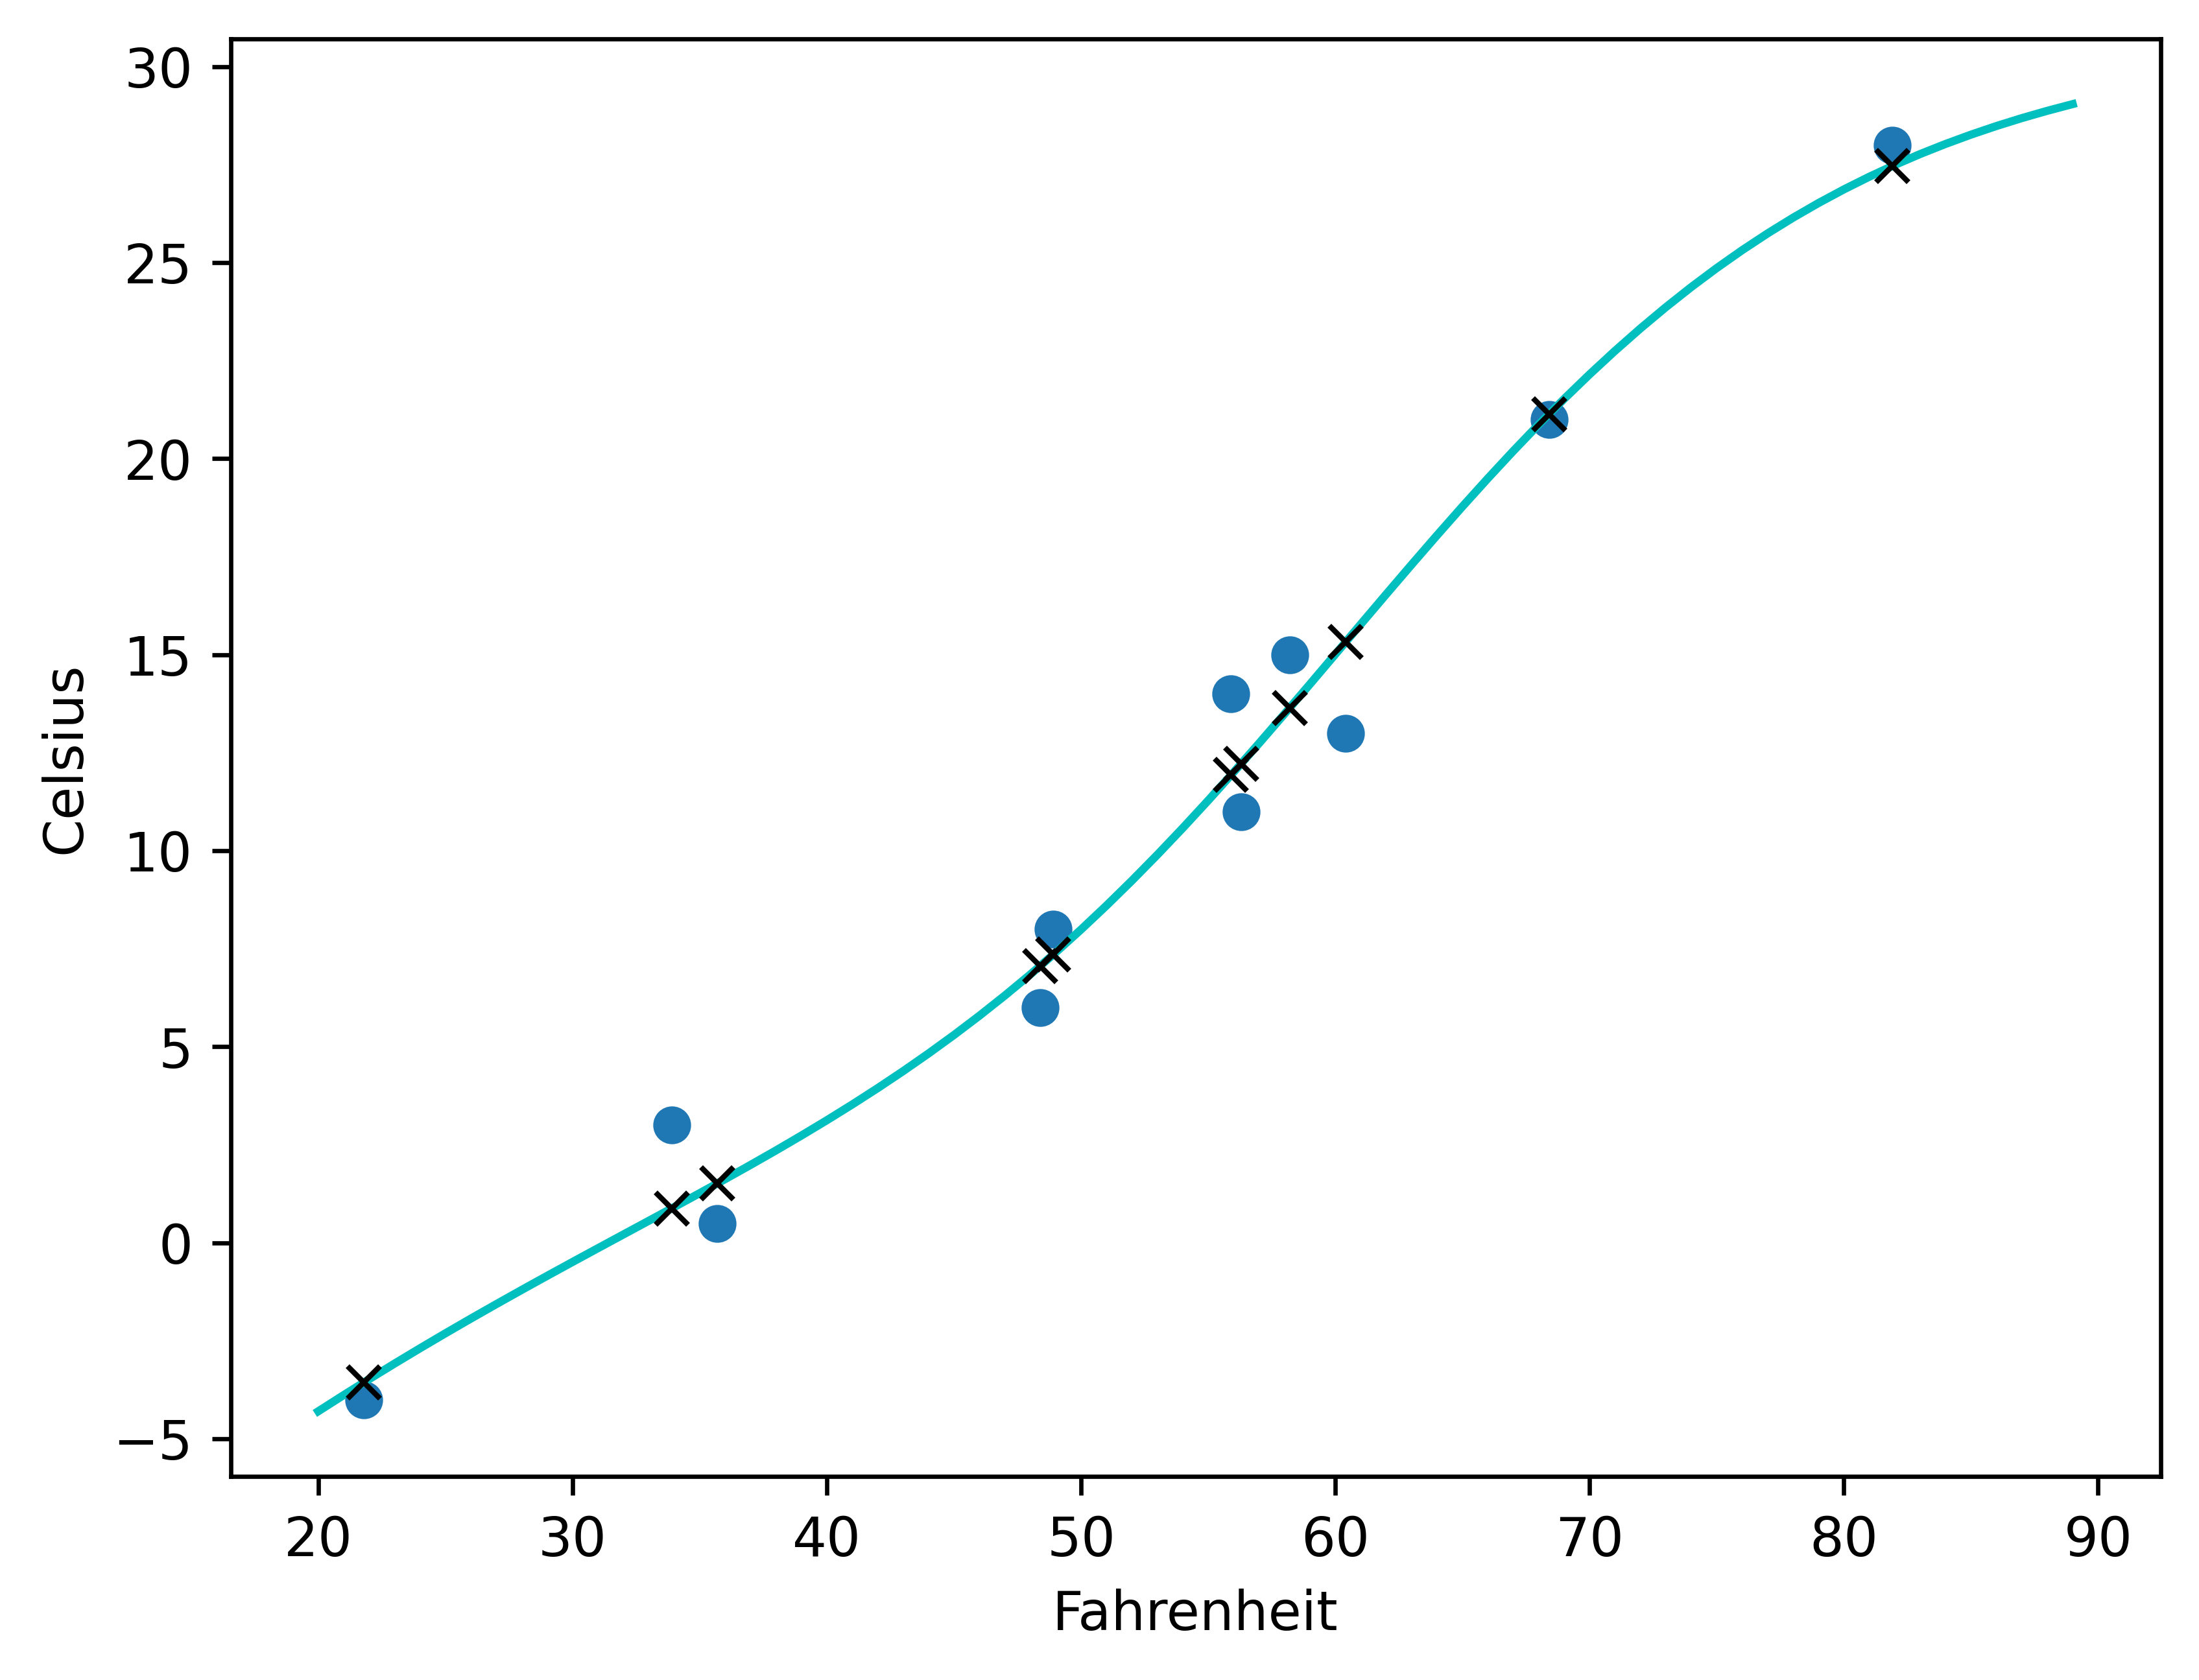

In [13]:
from matplotlib import pyplot as plt

t_range = torch.arange(20., 90.).unsqueeze(1)

fig = plt.figure(dpi=600)

plt.xlabel('Fahrenheit')
plt.ylabel('Celsius')
plt.plot(t_u.numpy(), t_c.numpy(), 'o')
plt.plot(t_range.numpy(), seq_model(0.1 * t_range).detach().numpy(), 'c-')
plt.plot(t_u.numpy(), seq_model(0.1 * t_u).detach().numpy(), 'kx')

seq_model(10)

## Exercises

### 1

1. Experiment with the number of hidden neurons (Output features) in our simple neural network model, as well as the learning rate. \
a.  What changes result in more linear output from the model? \
--> I assume less neurons = more linear. This is true, but output becomes a horizontal straight line. Similar results with very big lr? --> Not enough capacity to learn from data \
b.  Can you get the model to obviously overfit the data? \
--> I assume more neurons will cause overfitting. True. Also, at a certain point the lr becomes too big for the # the models weight updates become too large and result in NaN error.

In [ ]:
# Imports
import torch
import torch.optim as optim
import torch.nn as nn

# # Data
# t_c = [0.5, 14.0, 15.0, 28.0, 11.0, 8.0, 3.0, -4.0, 6.0, 13.0, 21.0]
# t_u = [35.7, 55.9, 58.2, 81.9, 56.3, 48.9, 33.9, 21.8, 48.4, 60.4, 68.4]

# t_c = torch.tensor(t_c).unsqueeze(1) 
# t_u = torch.tensor(t_u).unsqueeze(1)

# t_c.shape, t_u.shape

# Model 
seq_model = nn.Sequential(nn.Linear(1, 20),
                          nn.Tanh(),
                          nn.Linear(20, 1))

optimizer = optim.SGD(seq_model.parameters(), 
                      lr = 1e-3)

def training_loop(n_epochs, model, optimizer, loss_fn, t_u_train, t_u_val, t_c_train, t_c_val):
    for epoch in range(1, n_epochs + 1):
        train_prediction = model(t_u_train)
        train_loss = loss_fn(train_prediction, t_c_train)

        with torch.no_grad():
            val_prediction = model(t_u_val)
            val_loss = loss_fn(val_prediction, t_c_val)

        optimizer.zero_grad()
        train_loss.backward()
        optimizer.step()

        if epoch <= 3 or epoch % 1000 == 0:
            print(f'EPOCH {epoch} train loss: {train_loss}, val loss: {val_loss}')

training_loop(
    n_epochs= 5000,
    model= seq_model,
    optimizer= optimizer,
    loss_fn= nn.MSELoss(),
    t_u_train = t_un_train,
    t_u_val = t_un_val,
    t_c_train = t_c_train,
    t_c_val = t_c_val)

print('output', seq_model(t_un_val))
print('answer', t_c_val)

# print(f'params: {[param for param in seq_model.parameters()]}')

# Plot Model
%matplotlib inline
from matplotlib import pyplot as plt

t_range = torch.arange(20., 90.).unsqueeze(1)

fig = plt.figure(dpi=600)

plt.xlabel('Fahrenheit')
plt.ylabel('Celsius')
plt.plot(t_u.numpy(), t_c.numpy(), 'o')
plt.plot(t_range.numpy(), seq_model(0.1 * t_range).detach().numpy(), 'c-')
plt.plot(t_u.numpy(), seq_model(0.1 * t_u).detach().numpy(), 'kx')

### 2

Load the wine data from chapter 4, and create a new model with the appropriate number of input parameters. \
a. How long does it take to train compared to the temperature data we have been using? -- Not much longer, even though its much bigger \
b. Can you explain what factors contribute to the training times? -- # Epochs and # Neurons --> More computations as they incease\
c. Can you get the loss to decrease while training on this dataset? -- Yes, experemented with one hot / score vector and diffrent # neurons\
d. How would you go about graphing this dataset?
--> Could probably (use the model to) determine the 2 fetures that have the greatest influence on the score, and then do a 3D scatterplot with those 2 features, the models predictions, and the actual predections.

In [ ]:
# Imports
import torch
import torch.optim as optim
import torch.nn as nn
import numpy as np
import csv

In [27]:
# Loading wine data
data_path = 'data/ch4/tabular-wine/winequality-white.csv'
wineq_np = np.loadtxt(data_path, dtype=np.float32, delimiter=';', skiprows=1)
wineq_np

# Extracting col headders
col_list = next(csv.reader(open(data_path), delimiter=';'))
wineq_np.shape, col_list

# Moving data to tensors
wineq = torch.from_numpy(wineq_np)
wineq.shape, wineq.dtype

# Seperating data and scores -- Moving Wine Quality to seperate tensor 
data = wineq[:, :-1]
target = wineq[:, -1]

target, target.shape

# Creating one-hot encoding of targets to compare
target_onehot = torch.zeros(target.shape[0], 10)
target_onehot.scatter_(1, target.long().unsqueeze(1), 1.0)

# Reshaping target to match data
# target = target.view(-1, 1) #Same as below!
target = target.unsqueeze(1) 

# Normalising data -- Using z-score normalisation
data_n = (data - data.mean()) / data.std()

data_n.shape, target.shape, target_onehot.shape

(torch.Size([4898, 11]), torch.Size([4898, 1]), torch.Size([4898, 10]))

In [128]:
# Creating Model, Optimizer, and loss_fn
model = nn.Sequential(nn.Linear(data.shape[1], 10),
              nn.ReLU(),
              nn.Linear(10, 1))

lr = 1e-3
optimizer = optim.Adam(model.parameters(), lr= lr)

loss_fn = nn.MSELoss()

In [127]:
# Training Troubleshooting

# Checking if there are NaN or Inf values in the data or target
print(torch.isnan(data).any())  # Check if any NaN values in input
print(torch.isnan(target).any())  # Check if any NaN values in target
print(torch.isinf(data).any())  # Check if any Inf values in input
print(torch.isinf(target).any())  # Check if any Inf values in target

# Checking model doesn't return NaN
prediction = model(data)
print(prediction)  # Check the outputs of the model

loss = loss_fn(prediction, target)
print(loss)

tensor(False)
tensor(False)
tensor(False)
tensor(False)
tensor([[-179.5069],
        [ -77.7887],
        [-107.2776],
        ...,
        [ -44.7341],
        [ -43.2543],
        [ -40.3696]], grad_fn=<AddmmBackward0>)
tensor(11737.7471, grad_fn=<MseLossBackward0>)


In [129]:
# Training Loop
def training_loop(n_epochs, model, optimizer, loss_fn, data, ground_truth):    

    # # Move all data and model to gpu
    # device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    # print(f"Using Device: {torch.cuda.current_device()} - {torch.cuda.get_device_name(device)}")
    
    # data = data.to(device)
    # ground_truth = ground_truth.to(device)
    # model = model.to(device)

    for epoch in range(1, n_epochs + 1):
        prediction = model(data)
        loss = loss_fn(prediction, ground_truth)

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if epoch < 3 or epoch % 2500 ==0:
            print(f'EPOCH {epoch}: Loss = {loss}')

training_loop(
    n_epochs= 10000,
    model= model,
    optimizer= optimizer,
    loss_fn= loss_fn,
    data = data_n,
    ground_truth= target)

EPOCH 1: Loss = 35.63518142700195
EPOCH 2: Loss = 35.52622985839844
EPOCH 2500: Loss = 0.7503936886787415
EPOCH 5000: Loss = 0.6649330854415894
EPOCH 7500: Loss = 0.5761507153511047
EPOCH 10000: Loss = 0.5714067220687866


In [136]:
# Test the model with the 11th sample (index 10)
sample = 7
prediction = model(data_n[sample, :].unsqueeze(0))  # Add batch dimension
print(f"Predicted: {prediction.item()} | Actual: {target[sample].item()}")

Predicted: 5.573119163513184 | Actual: 6.0


In [94]:
# Training with scores encoded as one-hot to compare
import torch.nn.functional as F

def training_loop(n_epochs, model, optimizer, loss_fn, data, ground_truth):    

    # # Move all data and model to gpu
    # device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    # print(f"Using Device: {torch.cuda.current_device()} - {torch.cuda.get_device_name(device)}")
    
    # data = data.to(device)
    # ground_truth = ground_truth.to(device)
    # model = model.to(device)

    for epoch in range(1, n_epochs + 1):
        prediction = model(data)
        # prediction = F.softmax(model_output, dim=1)
        loss = loss_fn(prediction, ground_truth.argmax(dim=1))

        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        if epoch < 3 or epoch % 2500 ==0:
            print(f'EPOCH {epoch}: Loss = {loss}')


model = nn.Sequential(nn.Linear(data.shape[1], 100),
              nn.ReLU(),
              nn.Linear(100, 10))

lr = 1e-3
optimizer = optim.Adam(model.parameters(), lr= lr)


training_loop(
    n_epochs= 10000,
    model= model,
    optimizer= optimizer,
    loss_fn= nn.CrossEntropyLoss(),
    data = data_n,
    ground_truth= target_onehot)

EPOCH 1: Loss = 2.3045079708099365
EPOCH 2: Loss = 2.267648935317993
EPOCH 2500: Loss = 1.0697360038757324
EPOCH 5000: Loss = 1.043260931968689
EPOCH 7500: Loss = 1.024126410484314
EPOCH 10000: Loss = 1.012198805809021


In [95]:
# Test the model with the 11th sample (index 10)
model_output = model(data_n[10, :].unsqueeze(0))  # Add batch dimension
# prediction = F.softmax(model_output, dim=1)
print(f"Predicted: {prediction.argmax(dim=1)} | Actual: {target_onehot[10]}")

Predicted: tensor([6]) | Actual: tensor([0., 0., 0., 0., 0., 1., 0., 0., 0., 0.])
